# Dataset exploration



This notebook profiles the locally available TechQA training data for Domain Adapation. Each analysis step is kept in a separate cell so the workflow is easy to run, inspect, and extend.

## Imports and dataset loading paths

In [2]:
import json
import bz2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Locate and inspect dataset files

In [3]:
# Locate project root without changing the working directory

PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data/raw/TechQA").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("TechQA dataset directory not found.")

TECHQA_PATH = PROJECT_ROOT / "data/raw/TechQA"
QA_PATH = TECHQA_PATH / "training_and_dev"

print("Project root:", PROJECT_ROOT)
print("TechQA directory:", TECHQA_PATH)
print("\nQuestion and answer files:")

for file in sorted(QA_PATH.iterdir()):
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / (1024**2), 2), "MB")

print("\nTechnical document corpus:")

corpus_path = (
    TECHQA_PATH
    / "technote_corpus"
    / "full_technote_collection.txt.bz2"
)

print("Exists:", corpus_path.exists())

if corpus_path.exists():
    print("Size:", round(corpus_path.stat().st_size / (1024**2), 2), "MB")

Project root: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-
TechQA directory: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/TechQA

Question and answer files:
dev_Q_A.json - 0.53 MB
training_Q_A.json - 1.1 MB
training_Q_A.txt - 0.3 MB
training_dev_technotes.json - 278.43 MB
training_dev_technotes.sections.json - 227.94 MB

Technical document corpus:
Exists: True
Size: 794.53 MB


## 2. Loading Training and Development Question Datasets

In [5]:
# Load question-answer datasets

with open(QA_PATH / "training_Q_A.json", "r", encoding="utf-8") as f:
    train_questions = json.load(f)

with open(QA_PATH / "dev_Q_A.json", "r", encoding="utf-8") as f:
    dev_questions = json.load(f)

# Convert to DataFrames
train_df = pd.DataFrame(train_questions)
dev_df = pd.DataFrame(dev_questions)

print("Training questions:", len(train_df))
print("Development questions:", len(dev_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nDevelopment columns:")
print(dev_df.columns.tolist())

Training questions: 600
Development questions: 310

Training columns:
['QUESTION_ID', 'QUESTION_TITLE', 'QUESTION_TEXT', 'DOCUMENT', 'ANSWER', 'START_OFFSET', 'END_OFFSET', 'ANSWERABLE', 'DOC_IDS']

Development columns:
['QUESTION_ID', 'QUESTION_TITLE', 'QUESTION_TEXT', 'DOCUMENT', 'ANSWER', 'START_OFFSET', 'END_OFFSET', 'ANSWERABLE', 'DOC_IDS']


## 3. Schema and Sample Inspection

In [8]:
print("TRAINING DATA")
display(train_df.head(5))

print("\nTRAINING DATA TYPES")
display(train_df.dtypes.to_frame("Data Type"))

print("\nSAMPLE QUESTION RECORD")
display(train_questions[0])

TRAINING DATA


,QUESTION_ID,QUESTION_TITLE,QUESTION_TEXT,DOCUMENT,ANSWER,START_OFFSET,END_OFFSET,ANSWERABLE,DOC_IDS
0,TRAIN_Q000,User environment variables no longer getting p...,\n\nHave you found that after upgrade to Strea...,swg21996508,"To work around the issue, set environment vari...",822,1055,Y,"[swg21619105, swg27038498, swg1PK69015, swg219..."
1,TRAIN_Q001,Netcool/Impact (all versions): How is the Exit...,Netcool/Impact (all versions)\n\nUsing the Exi...,swg21675316,This is because the Exit() parser function in ...,494,763,Y,"[swg1IY90609, swg1IZ42549, swg21418544, swg1IZ..."
2,TRAIN_Q002,Why are replies going to the DLQ with reason 2...,I have changed my cluster receiver to match th...,-,-,-,-,N,"[swg1PK33560, swg1IT24269, swg1PK98245, swg216..."
3,TRAIN_Q003,How to configure SSL mutual authentication in ...,\n\nWe are running IHS v7 and our application ...,swg21179559,The following steps help guide you through the...,649,1322,Y,"[swg21405908, swg21670474, swg21660286, swg219..."
4,TRAIN_Q004,Help with Action required for IIB H.E. V9 & WM...,\n\nI need to understand details regarding Act...,-,-,-,-,N,"[swg22005035, swg21695798, swg21992475, swg220..."



TRAINING DATA TYPES


,Data Type
QUESTION_ID,str
QUESTION_TITLE,str
QUESTION_TEXT,str
DOCUMENT,str
ANSWER,str
START_OFFSET,str
END_OFFSET,str
ANSWERABLE,str
DOC_IDS,object



SAMPLE QUESTION RECORD


{'QUESTION_ID': 'TRAIN_Q000',
 'QUESTION_TITLE': 'User environment variables no longer getting picked up after upgrade to 4.1.1.1 or 4.1.1.2?',
 'QUESTION_TEXT': '\n\nHave you found that after upgrade to Streams 4.1.1.1 or 4.1.1.2, that environment variables set in your .bashrc are no longer being set? For example ODBCINI is not set for the database toolkit and you get\n\n     An SQL operation failed. The SQL state is 08003, the SQL code\n     is 0 and the SQL message is [unixODBC][Driver\n     Manager]Connnection does not exist.\n',
 'DOCUMENT': 'swg21996508',
 'ANSWER': 'To work around the issue, set environment variables that are needed by the application directly in the instance with:  * \n   \n * streamtool setproperty\n * -d <domain> -i <instance>\n   --application-ev <VARIABLE NAME>=<VARIABLE VALUE>',
 'START_OFFSET': '822',
 'END_OFFSET': '1055',
 'ANSWERABLE': 'Y',
 'DOC_IDS': ['swg21619105',
  'swg27038498',
  'swg1PK69015',
  'swg21996508',
  'swg1PK77738',
  'swg21585722',


In [7]:
print("\nDEVELOPMENT DATA")
display(dev_df.head(5))

print("\nDEVELOPMENT DATA TYPES")
display(dev_df.dtypes.to_frame("Data Type"))


DEVELOPMENT DATA


,QUESTION_ID,QUESTION_TITLE,QUESTION_TEXT,DOCUMENT,ANSWER,START_OFFSET,END_OFFSET,ANSWERABLE,DOC_IDS
0,DEV_Q000,Web GUI 8.1 FP7 requires DASH 3.1.2.1 or later,"\n\nYou wanted to install Web GUI 8.1 FP7, but...",swg24042191,Version 1.1.3.0 is a full refresh of Jazz for ...,955,1057,Y,"[swg24042191, swg21681385, swg21960632, swg219..."
1,DEV_Q001,"What can be done about ""Too many open files"" m...","What can be done about ""Too many open files"" m...",-,-,-,-,N,"[swg21968787, swg21588099, swg1PM86570, swg1JR..."
2,DEV_Q002,Unable to open profile from P8 Content Engine ...,\n\nLaunch configmgr then try to open an exist...,swg21978390,"Install the missing libraries ""adwaita-gtk2-th...",706,860,Y,"[swg21598554, swg21673044, swg1IO10742, swg1IC..."
3,DEV_Q003,Is there a way set a timeout for shell task?,I have run into couple of shell task in Urbanc...,-,-,-,-,N,"[swg21663259, swg1LO68498, swg21686886, isg3T1..."
4,DEV_Q004,Error #2070,I purchased the SPSS grad pack and put one of ...,-,-,-,-,N,"[swg1PI29943, swg1PI29944, swg1PI20755, swg1PI..."



DEVELOPMENT DATA TYPES


,Data Type
QUESTION_ID,str
QUESTION_TITLE,str
QUESTION_TEXT,str
DOCUMENT,str
ANSWER,str
START_OFFSET,str
END_OFFSET,str
ANSWERABLE,str
DOC_IDS,object


## 4. Missing Values and Duplicate Analysis

This section examines missing values, duplicate records and duplicate question IDs in the training and development datasets.

In [10]:
def inspect_data_quality(data, dataset_name):
    print(f"\n{'='*50}")
    print(dataset_name)
    print(f"{'='*50}")

    print("Total records:", len(data))

    # Missing values
    print("\nMissing values:")
    display(data.isnull().sum().to_frame("Missing Count"))

    # Duplicate rows - safely handles lists and dictionaries
    row_signatures = data.apply(
        lambda row: json.dumps(
            row.to_dict(),
            sort_keys=True,
            default=str
        ),
        axis=1
    )

    print("\nDuplicate rows:", row_signatures.duplicated().sum())

    # Duplicate question IDs
    id_columns = [
        col for col in data.columns
        if col.lower() in ["id", "question_id", "qid"]
    ]

    for col in id_columns:
        print(
            f"Duplicate {col} values:",
            data[col].duplicated().sum()
        )


inspect_data_quality(train_df, "TRAINING DATA")
inspect_data_quality(dev_df, "DEVELOPMENT DATA")


TRAINING DATA
Total records: 600

Missing values:


,Missing Count
QUESTION_ID,0
QUESTION_TITLE,0
QUESTION_TEXT,0
DOCUMENT,0
ANSWER,0
START_OFFSET,0
END_OFFSET,0
ANSWERABLE,0
DOC_IDS,0



Duplicate rows: 0
Duplicate QUESTION_ID values: 0

DEVELOPMENT DATA
Total records: 310

Missing values:


,Missing Count
QUESTION_ID,0
QUESTION_TITLE,0
QUESTION_TEXT,0
DOCUMENT,0
ANSWER,0
START_OFFSET,0
END_OFFSET,0
ANSWERABLE,0
DOC_IDS,0



Duplicate rows: 0
Duplicate QUESTION_ID values: 0


## 5. Answerability Distribution

This section analyses the distribution of answerable and unanswerable questions in the training and development datasets.

In [11]:
# Inspect answerability values first

print("Training answerability values:")
print(train_df["ANSWERABLE"].value_counts(dropna=False))

print("\nDevelopment answerability values:")
print(dev_df["ANSWERABLE"].value_counts(dropna=False))

Training answerability values:
ANSWERABLE
Y    450
N    150
Name: count, dtype: int64

Development answerability values:
ANSWERABLE
Y    160
N    150
Name: count, dtype: int64


In [12]:
# Compare answerability distributions

train_counts = train_df["ANSWERABLE"].value_counts()
dev_counts = dev_df["ANSWERABLE"].value_counts()

answerability_comparison = pd.DataFrame({
    "Training": train_counts,
    "Development": dev_counts
}).fillna(0).astype(int)

display(answerability_comparison)

# Percentage distribution
answerability_percentage = pd.DataFrame({
    "Training (%)": train_df["ANSWERABLE"].value_counts(normalize=True) * 100,
    "Development (%)": dev_df["ANSWERABLE"].value_counts(normalize=True) * 100
}).fillna(0).round(2)

display(answerability_percentage)

,Training,Development
ANSWERABLE,,
Y,450,160
N,150,150


,Training (%),Development (%)
ANSWERABLE,,
Y,75.0,51.61
N,25.0,48.39


Visualisation:

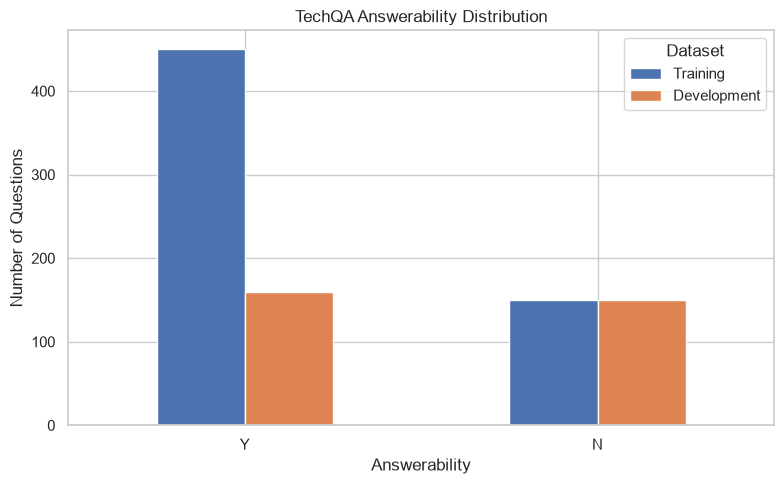

In [13]:
answerability_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("TechQA Answerability Distribution")
plt.xlabel("Answerability")
plt.ylabel("Number of Questions")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

## 6. Question Length Analysis

This section analyses the word and character lengths of questions in the training and development datasets.

In [14]:
# Calculate question lengths without modifying original text

train_df["question_words"] = train_df["QUESTION_TEXT"].apply(
    lambda x: len(str(x).split())
)

train_df["question_chars"] = train_df["QUESTION_TEXT"].apply(
    lambda x: len(str(x))
)

dev_df["question_words"] = dev_df["QUESTION_TEXT"].apply(
    lambda x: len(str(x).split())
)

dev_df["question_chars"] = dev_df["QUESTION_TEXT"].apply(
    lambda x: len(str(x))
)

print("Question length columns created.")

Question length columns created.


In [15]:
question_length_stats = pd.DataFrame({
    "Training": train_df["question_words"].describe(),
    "Development": dev_df["question_words"].describe()
})

display(question_length_stats)

,Training,Development
count,600.000000,310.000000
mean,39.466667,40.506452
std,31.244988,30.078726
min,1.000000,0.000000
25%,19.000000,21.000000
50%,29.000000,32.000000
75%,50.000000,49.000000
max,245.000000,175.000000


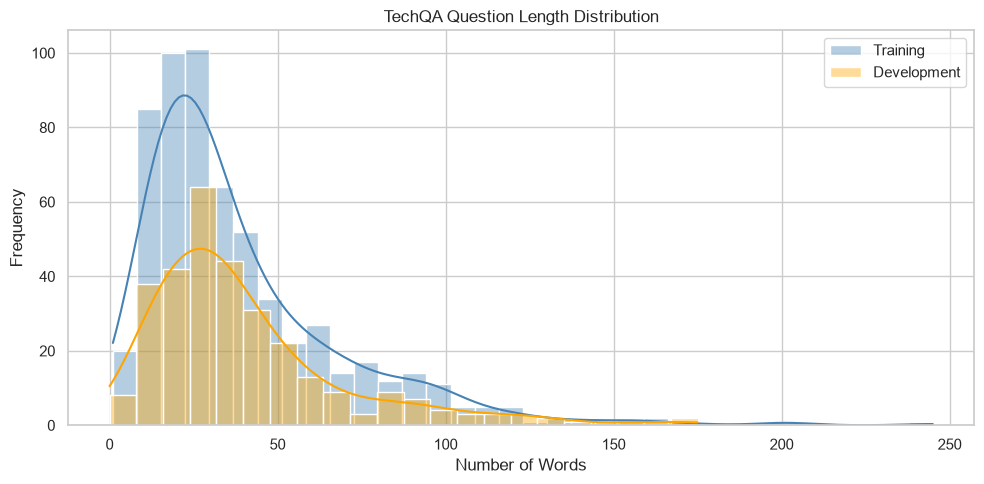

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="question_words",
    color="steelblue",
    label="Training",
    kde=True,
    alpha=0.4
)

sns.histplot(
    data=dev_df,
    x="question_words",
    color="orange",
    label="Development",
    kde=True,
    alpha=0.4
)

plt.title("TechQA Question Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Analyse document and answer lengths

In [19]:
# Compare document and answer length statistics

train_stats = train_df[
    ["DOCUMENT_LENGTH", "ANSWER_LENGTH"]
].describe().loc[["mean", "std", "min", "50%", "max"]]

dev_stats = dev_df[
    ["DOCUMENT_LENGTH", "ANSWER_LENGTH"]
].describe().loc[["mean", "std", "min", "50%", "max"]]

length_comparison = pd.concat(
    {
        "Training": train_stats,
        "Development": dev_stats
    },
    axis=1
)

display(length_comparison.round(2))

Training                   Development              
     DOCUMENT_LENGTH ANSWER_LENGTH DOCUMENT_LENGTH ANSWER_LENGTH
mean             1.0         36.33             1.0         21.42
std              0.0         38.58             0.0         28.18
min              1.0          1.00             1.0          0.00
50%              1.0         26.50             1.0          6.00
max              1.0        302.00             1.0        137.00

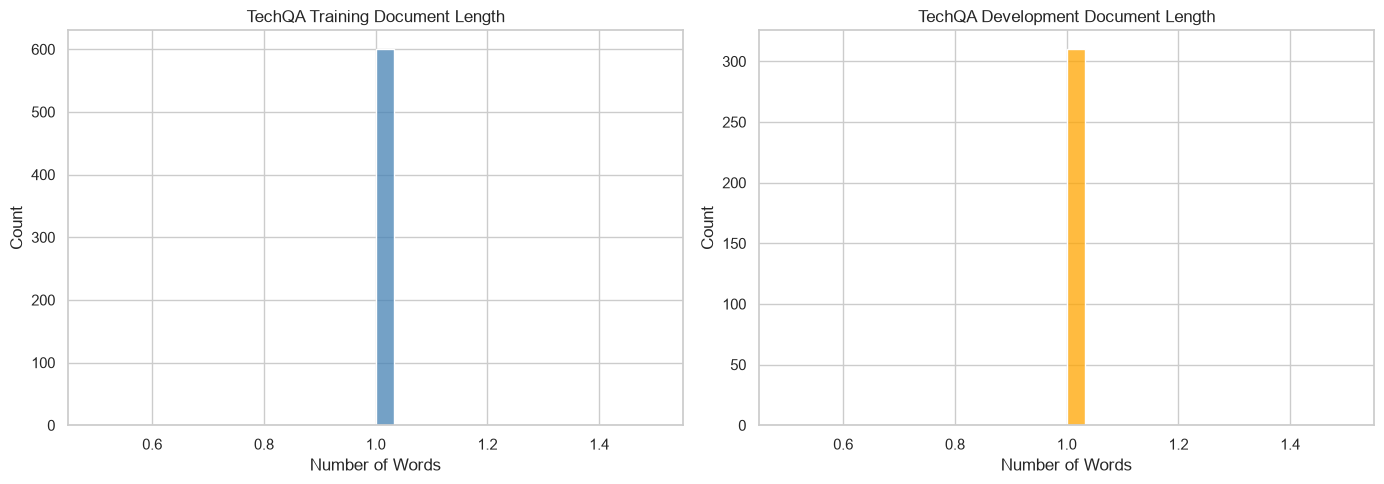

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train_df,
    x="DOCUMENT_LENGTH",
    bins=30,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("TechQA Training Document Length")
axes[0].set_xlabel("Number of Words")

sns.histplot(
    data=dev_df,
    x="DOCUMENT_LENGTH",
    bins=30,
    color="orange",
    ax=axes[1]
)

axes[1].set_title("TechQA Development Document Length")
axes[1].set_xlabel("Number of Words")

plt.tight_layout()
plt.show()

In [21]:
for name, df in [
    ("Training", train_df),
    ("Development", dev_df)
]:
    print(f"\n{name}")

    print(
        "Empty questions:",
        df["QUESTION_TEXT"].fillna("").str.strip().eq("").sum()
    )

    print(
        "Empty documents:",
        df["DOCUMENT"].fillna("").str.strip().eq("").sum()
    )

    print(
        "Empty answers:",
        df["ANSWER"].fillna("").str.strip().eq("").sum()
    )


Training
Empty questions: 0
Empty documents: 0
Empty answers: 0

Development
Empty questions: 1
Empty documents: 0
Empty answers: 2


In [22]:
# Inspect DOCUMENT column structure

print("TRAINING DOCUMENT")

for i in range(3):
    value = train_df["DOCUMENT"].iloc[i]

    print(f"\nRecord {i + 1}")
    print("Type:", type(value))
    print("Value:", repr(value)[:1000])


print("\nDEVELOPMENT DOCUMENT")

for i in range(3):
    value = dev_df["DOCUMENT"].iloc[i]

    print(f"\nRecord {i + 1}")
    print("Type:", type(value))
    print("Value:", repr(value)[:1000])

TRAINING DOCUMENT

Record 1
Type: <class 'str'>
Value: 'swg21996508'

Record 2
Type: <class 'str'>
Value: 'swg21675316'

Record 3
Type: <class 'str'>
Value: '-'

DEVELOPMENT DOCUMENT

Record 1
Type: <class 'str'>
Value: 'swg24042191'

Record 2
Type: <class 'str'>
Value: '-'

Record 3
Type: <class 'str'>
Value: 'swg21978390'


In [23]:
display(
    train_df[
        ["QUESTION_ID", "QUESTION_TEXT", "DOCUMENT", "ANSWER"]
    ].head(3)
)

,QUESTION_ID,QUESTION_TEXT,DOCUMENT,ANSWER
0,TRAIN_Q000,\n\nHave you found that after upgrade to Strea...,swg21996508,"To work around the issue, set environment vari..."
1,TRAIN_Q001,Netcool/Impact (all versions)\n\nUsing the Exi...,swg21675316,This is because the Exit() parser function in ...
2,TRAIN_Q002,I have changed my cluster receiver to match th...,-,-


In [25]:
from pathlib import Path

TECHQA_PATH = Path("data/raw/TechQA")

print("TechQA directory exists:", TECHQA_PATH.exists())

print("\nFiles and folders inside TechQA:")

for item in TECHQA_PATH.rglob("*"):
    if item.is_file() and "technotes" in item.name.lower():
        print("\nFile:", item.name)
        print("Actual path:", item)
        print("Size (MB):", round(item.stat().st_size / (1024 * 1024), 2))

TechQA directory exists: False

Files and folders inside TechQA:


In [26]:
from pathlib import Path
import os

print("Current working directory:")
print(os.getcwd())

print("\nProject directory check:")

PROJECT_PATH = Path(
    "/Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-"
)

print("Project exists:", PROJECT_PATH.exists())

TECHQA_PATH = PROJECT_PATH / "data" / "raw" / "TechQA"

print("TechQA exists:", TECHQA_PATH.exists())

if TECHQA_PATH.exists():
    print("\nTechQA contents:")
    for item in TECHQA_PATH.iterdir():
        print(item.name)

Current working directory:
/Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/notebooks/01_exploration

Project directory check:
Project exists: True
TechQA exists: True

TechQA contents:
evaluation.py
CDLA-Permissive-v1.0.pdf
training_and_dev
README.txt
technote_corpus
validation


In [27]:
from pathlib import Path

PROJECT_PATH = Path(
    "/Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-"
)

TECHQA_PATH = PROJECT_PATH / "data" / "raw" / "TechQA"

CORPUS_PATH = TECHQA_PATH / "technote_corpus"

print("Corpus folder exists:", CORPUS_PATH.exists())

print("\nFiles inside technical document corpus:")

if CORPUS_PATH.exists():
    for file in CORPUS_PATH.rglob("*"):
        if file.is_file():
            print(
                file.name,
                "|",
                round(file.stat().st_size / (1024 * 1024), 2),
                "MB"
            )

Corpus folder exists: True

Files inside technical document corpus:
CDLA-Permissive-v1.0.pdf | 0.09 MB
technotes.id_title_text | 2596.32 MB
full_technote_collection.txt.bz2 | 794.53 MB
full_technote_collection.sections.json | 6124.53 MB
technotes.text | 2240.96 MB


## Inspect document formats

In [29]:
from pathlib import Path

PROJECT_PATH = Path(
    "/Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-"
)

CORPUS_PATH = (
    PROJECT_PATH / "data/raw/TechQA/technote_corpus"
)

document_file = CORPUS_PATH / "technotes.id_title_text"

print("File exists:", document_file.exists())

with open(
    document_file,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:

    for i in range(3):
        line = f.readline()

        print(f"\nRecord {i+1}:")
        print("Characters:", len(line))
        print(line[:1500])

File exists: True

Record 1:
Characters: 17
====== ID ======


Record 2:
Characters: 12
swg1PK13560


Record 3:
Characters: 1




In [30]:
document_file = CORPUS_PATH / "technotes.id_title_text"

with open(
    document_file,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:
    for i in range(20):
        line = f.readline()
        print(f"Line {i+1}: {repr(line[:500])}")

Line 1: '====== ID ======\n'
Line 2: 'swg1PK13560\n'
Line 3: '\n'
Line 4: '====== TITLE ======\n'
Line 5: 'IBM PK13560: ILLEGAL MONITOR STATE EXCEPTION RAISED IN JIT COMPILED CODE - United States\n'
Line 6: '\n'
Line 7: '====== TEXT ======\n'
Line 8: 'AIX SUBSCRIBE\n'
Line 9: 'You can track all active APARs for this component.\n'
Line 10: '\n'
Line 11: '\n'
Line 12: '\n'
Line 13: 'APAR STATUS\n'
Line 14: ' * CLOSED AS PROGRAM ERROR.\n'
Line 15: '    \n'
Line 16: '   \n'
Line 17: '   \n'
Line 18: '\n'
Line 19: 'ERROR DESCRIPTION\n'
Line 20: ' *  The customer reported an\n'


In [31]:
from pathlib import Path
import pandas as pd

# Locate the actual corpus
PROJECT_ROOT = Path.cwd().parents[1]

corpus_file = (
    PROJECT_ROOT
    / "data/raw/TechQA/technote_corpus/technotes.id_title_text"
)

print("File exists:", corpus_file.exists())


def parse_technotes(file_path):
    documents = []
    current = None
    section = None

    with open(file_path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            value = line.rstrip("\n")

            if value.strip() == "====== ID ======":
                if current is not None:
                    documents.append(current)

                current = {"ID": "", "TITLE": "", "TEXT": ""}
                section = "ID"

            elif value.strip() == "====== TITLE ======":
                section = "TITLE"

            elif value.strip() == "====== TEXT ======":
                section = "TEXT"

            elif current is not None and section:
                current[section] += value + "\n"

        if current is not None:
            documents.append(current)

    return documents


documents = parse_technotes(corpus_file)

documents_df = pd.DataFrame(documents)

documents_df["DOCUMENT_LENGTH"] = (
    documents_df["TEXT"].str.split().str.len()
)

print("Total documents:", len(documents_df))
display(documents_df[
    ["ID", "TITLE", "DOCUMENT_LENGTH"]
].head())

print(documents_df["DOCUMENT_LENGTH"].describe())

File exists: True
Total documents: 801996


,ID,TITLE,DOCUMENT_LENGTH
0,swg1PK13560\n\n,IBM PK13560: ILLEGAL MONITOR STATE EXCEPTION R...,190
1,swg1PQ99674\n\n,IBM PQ99674: COMBO BOXES ARE NOT MIRRORED CORR...,210
2,swg1PI92837\n\n,IBM PI92837: SQLCODE -805 FOR SQL OPERATION ON...,477
3,swg1OW48999\n\n,IBM OW48999: NOT CLEARED CHILD EVENT CAUSES A ...,490
4,swg1PK80899\n\n,IBM PK80899: WEBSTART MALFORMED URL EXCEPTION ...,322


count    801996.000000
mean        366.353902
std         666.694893
min           1.000000
25%         200.000000
50%         285.000000
75%         403.000000
max       87013.000000
Name: DOCUMENT_LENGTH, dtype: float64


In [33]:
# 1. Clean document IDs
documents_df["ID"] = documents_df["ID"].str.strip()

train_df["DOCUMENT"] = train_df["DOCUMENT"].astype(str).str.strip()
dev_df["DOCUMENT"] = dev_df["DOCUMENT"].astype(str).str.strip()

# 2. Check document ID matching
corpus_ids = set(documents_df["ID"])

print("TRAINING")
print("Total records:", len(train_df))
print("Matched documents:", train_df["DOCUMENT"].isin(corpus_ids).sum())
print("Unmatched documents:", (~train_df["DOCUMENT"].isin(corpus_ids)).sum())

print("\nDEVELOPMENT")
print("Total records:", len(dev_df))
print("Matched documents:", dev_df["DOCUMENT"].isin(corpus_ids).sum())
print("Unmatched documents:", (~dev_df["DOCUMENT"].isin(corpus_ids)).sum())

# 3. Investigate unusually long documents
print("\nTOP 10 LONGEST DOCUMENTS")
display(
    documents_df.nlargest(10, "DOCUMENT_LENGTH")[
        ["ID", "TITLE", "DOCUMENT_LENGTH"]
    ]
)

TRAINING
Total records: 600
Matched documents: 450
Unmatched documents: 150

DEVELOPMENT
Total records: 310
Matched documents: 160
Unmatched documents: 150

TOP 10 LONGEST DOCUMENTS


,ID,TITLE,DOCUMENT_LENGTH
608696,swg21412438,"IBM Fix List for DB2 Version 9.7 for Linux, UN...",87013
2249,swg27014463,IBM Fix list for IBM WebSphere Application Ser...,77562
1628,swg27049974,IBM Fix list for Rational Performance Test Ser...,75765
428585,swg27049973,IBM Fix list for Rational Test Virtualization ...,75285
1590,swg27049967,IBM Fix list for Rational Integration Tester -...,73715
76734,swg22016203,IBM PI96947: IBM z/OS Connect Enterprise Editi...,72617
788020,swg27036319,IBM Fix list for IBM WebSphere Application Ser...,71084
799421,swg22008852,IBM Updates for Maximo Asset Management 7.6 fe...,63575
46421,swg22011381,IBM P190096: New open source and IBM WebSphere...,59303
1195,swg27023148,IBM Fix list for Rational ClearCase - United S...,58072


## Final EDA Findings – TechQA

### 1. Dataset Overview
- Training split: 600 questions.
- Development split: 310 questions.
- The dataset contains technical-support questions and associated document identifiers.
- The companion Technote corpus was parsed and inspected separately.
- The original TechQA test set is not publicly available.

### 2. Data Quality
- No missing values were found in the inspected dataset fields.
- No duplicate rows were identified.
- No duplicate question IDs were identified.
- One empty/whitespace question was found in the development split.
- Two empty answers were found in the development split.

### 3. Answerability Distribution

**Training:**
- Answerable: 450 (75%).
- Unanswerable: 150 (25%).

**Development:**
- Answerable: 160 (51.61%).
- Unanswerable: 150 (48.39%).

The development split has a substantially higher proportion of unanswerable questions than the training split. This difference is important when evaluating the model's ability to abstain from answering.

### 4. Question Length Analysis

Word-count statistics:

| Statistic | Train | Development |
|---|---:|---:|
| Mean | 39.47 | 40.51 |
| Median | 29 | 32 |
| Minimum | 1 | 0 |
| Maximum | 245 | 175 |

- Development questions are slightly longer on average.
- Both splits contain considerable variation in question length.
- The empty development question accounts for the minimum length of zero.

### 5. Answer Length Analysis

Word-count statistics:

| Statistic | Train | Development |
|---|---:|---:|
| Mean | 36.33 | 21.42 |
| Median | 26.5 | 6 |
| Maximum | 302 | 137 |

- Training answers are longer on average than development answers.
- The median answer length differs considerably between the splits.
- Some answers are substantially longer than typical short extractive answers.

### 6. Technote Corpus Analysis
- The actual Technote corpus was located under `data/raw/TechQA/technote_corpus/`.
- The `technotes.id_title_text` file was parsed into document IDs, titles and text.
- Total parsed documents: 801,996.
- Mean document length: 366.35 words.
- Median document length: 285 words.
- 25th percentile: 200 words.
- 75th percentile: 403 words.
- Maximum document length: 87,013 words.

The corpus contains documents of varying lengths, including a small number of very long documents.

### 7. Question-to-Document Mapping
The `DOCUMENT` field in the QA dataset contains document identifiers, not document text.

After matching these identifiers against the parsed Technote corpus:

| Split | Total questions | Matched documents | Unmatched |
|---|---:|---:|---:|
| Train | 600 | 450 | 150 |
| Development | 310 | 160 | 150 |

- All unmatched records corresponded to unanswerable questions with `DOCUMENT = "-"`.
- Therefore, the unmatched records do not indicate failed document retrieval.
- The document mapping is consistent with the answerability distribution.

### 8. Limitations and Considerations
- TechQA has a relatively small labelled dataset, with only 600 training questions.
- The answerability proportions differ between training and development.
- Answer lengths vary considerably, which makes answer-span evaluation important.
- The Technote corpus contains very long documents, so context-window and truncation decisions will matter during preprocessing.
- Empty questions and answers in the development split require appropriate handling.
- No preprocessing, tokenization or model training was performed during this exploration.

### Conclusion
The exploratory analysis established the structure, data quality, answerability distribution and text characteristics of TechQA.

The Technote corpus was successfully parsed, and